In [17]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

# Sett sti til databasen i Kom - G2 prosjektet
DB_PATH = "./data/database/kostra_prod.duckdb"

# Koble til DuckDB i skrivebeskyttet modus
conn = duckdb.connect(DB_PATH, read_only=True)
print("✅ Koblet til DuckDB i read-only modus!")

✅ Koblet til DuckDB i read-only modus!


In [18]:

df = conn.execute("SELECT * FROM modelready_fact").fetchdf()
conn.close()  # Lukk tilkoblingen ryddig etter at dataene er hentet

In [3]:
from pycaret.regression import setup, compare_models, evaluate_model, interpret_model
# 2. Sett opp eksperimentet
exp_reg = setup(
    data=df, 
    target='target_next_month_regnskap',
    ignore_features=['accounting_period', 'source_file', 'batch_timestamp'],
    session_id=42
)

# 3. Sammenlign alle modeller og hent Top 3
best_top3_reg = compare_models(n_select=3, sort='RMSE')

# 4. Sjekk tolkbarhet med SHAP
interpret_model(best_top3_reg[0])

,Description,Value
0,Session id,42
1,Target,target_next_month_regnskap
2,Target type,Regression
3,Original data shape,"(2256, 31)"
4,Transformed data shape,"(2256, 56)"
5,Transformed train set shape,"(1579, 56)"
6,Transformed test set shape,"(677, 56)"
7,Ignore features,3
8,Numeric features,22
9,Categorical features,7


,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
knn,K Neighbors Regressor,11363.9438,3584464460.8000,51425.6896,-1.0249,3.3859,6.3311,0.1120
huber,Huber Regressor,11748.5084,3644449226.5935,52940.3770,-0.4913,3.3779,9.5823,0.1770
et,Extra Trees Regressor,11243.4506,3514253202.7430,54448.0461,-1.3126,3.3633,6.9141,1.0250
rf,Random Forest Regressor,11878.7049,3700881333.4114,54535.6445,-2.0479,3.4831,7.0681,1.4990
ada,AdaBoost Regressor,20770.5497,3821150727.7958,56394.0379,-1.5357,7.1387,66.8571,0.2390
omp,Orthogonal Matching Pursuit,16128.4890,4200815025.9447,57605.0425,-1.0428,6.7401,41.3461,0.1320
catboost,CatBoost Regressor,12688.8327,3871735896.1795,57739.6669,-1.4991,5.1182,9.2300,4.4870
br,Bayesian Ridge,15668.8251,4139011974.3380,57914.2311,-0.9380,6.4469,35.1295,0.1040
en,Elastic Net,16191.8396,4139818201.7924,58143.4383,-0.9935,6.2559,38.4049,0.1700
llar,Lasso Least Angle Regression,16326.9383,4168916164.5955,58224.5616,-0.9879,6.5362,38.2107,0.1590


TypeError: This function only supports tree based models for binary classification: catboost, rf, et, dt, lightgbm.

In [4]:
from pycaret.regression import plot_model

# Vis feature importances / koeffisienter for vinnermodellen
plot_model(best_top3_reg[0], plot='feature')

TypeError: Feature Importance and RFE plots not available for estimators that doesnt support coef_ or feature_importances_ attribute.

In [5]:
print(type(best_top3_reg[0]))
print(best_top3_reg[0])


<class 'sklearn.neighbors._regression.KNeighborsRegressor'>
KNeighborsRegressor(n_jobs=-1)


,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
et,Extra Trees Regressor,11243.4506,3514253202.7430,54448.0461,-1.3126,3.3633,6.9141,1.0280
rf,Random Forest Regressor,11878.7049,3700881333.4114,54535.6445,-2.0479,3.4831,7.0681,1.9360
gbr,Gradient Boosting Regressor,12954.5837,4578913436.0514,62553.0746,-3.6949,5.1475,6.8133,0.3510
dt,Decision Tree Regressor,14880.5322,6407992719.3445,74064.6201,-3.8422,3.4387,12.2327,0.1430


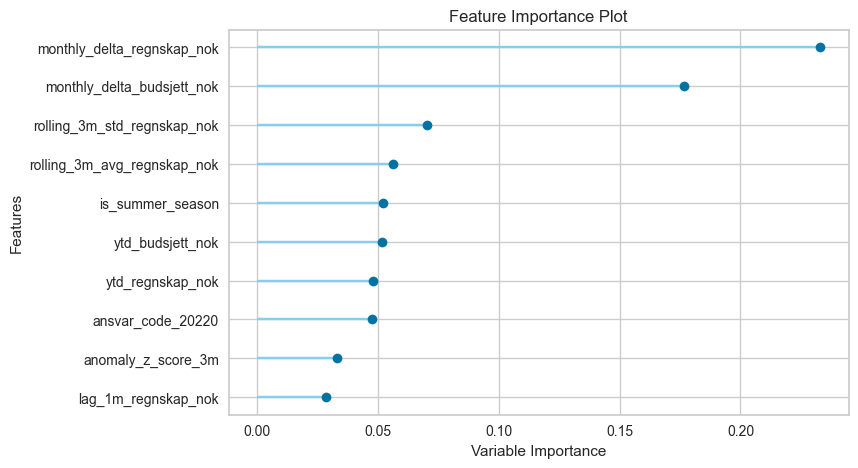

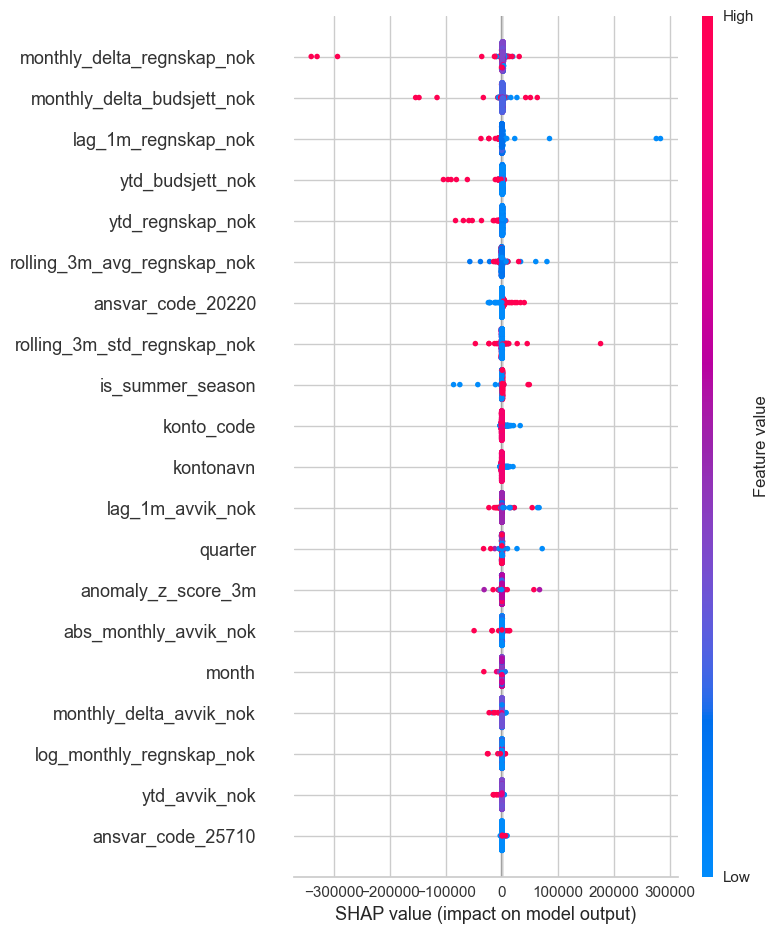

In [6]:
from pycaret.regression import compare_models, interpret_model, plot_model

# Sammenlign kun modeller med feature_importances_
best_top3_trees = compare_models(
    include=['rf', 'et', 'lightgbm', 'gbr', 'dt'], 
    n_select=3, 
    sort='RMSE'
)

# 1. Vis Feature Importance for den beste tre-modellen
plot_model(best_top3_trees[0], plot='feature')

# 2. Vis SHAP-forklaring
interpret_model(best_top3_trees[0])

In [7]:
from pycaret.classification import setup as setup_class, compare_models as compare_class

exp_clf = setup_class(
    data=df,
    target='target_status_code', # 0: I RUTE, 1: ADVARSEL, 2: KRITISK
    session_id=42
)

best_top3_clf = compare_class(n_select=3, sort='F1')

,Description,Value
0,Session id,42
1,Target,target_status_code
2,Target type,Binary
3,Original data shape,"(2256, 31)"
4,Transformed data shape,"(2256, 59)"
5,Transformed train set shape,"(1579, 59)"
6,Transformed test set shape,"(677, 59)"
7,Numeric features,22
8,Date features,1
9,Categorical features,7


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
ridge,Ridge Classifier,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.1420
qda,Quadratic Discriminant Analysis,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.1630
ada,Ada Boost Classifier,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.1830
gbc,Gradient Boosting Classifier,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.3220
et,Extra Trees Classifier,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.3840
catboost,CatBoost Classifier,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,5.7200
dt,Decision Tree Classifier,0.9994,0.9984,0.9969,1.0000,0.9984,0.9980,0.9980,0.1590
rf,Random Forest Classifier,0.9994,1.0000,0.9969,1.0000,0.9984,0.9980,0.9980,0.3400
lr,Logistic Regression,0.9968,0.9976,0.9938,0.9908,0.9922,0.9902,0.9903,2.7390
knn,K Neighbors Classifier,0.9335,0.9351,0.7562,0.8995,0.8197,0.7795,0.7852,0.1850


,Description,Value
0,Session id,42
1,Original data shape,"(2256, 31)"
2,Transformed data shape,"(2256, 199)"
3,Ignore features,6
4,Numeric features,23
5,Categorical features,4
6,Preprocess,True
7,Imputation type,simple
8,Numeric imputation,mean
9,Categorical imputation,mode


,Silhouette,Calinski-Harabasz,Davies-Bouldin,Homogeneity,Rand Index,Completeness
0,-0.0050,32.8208,4.9807,0,0,0


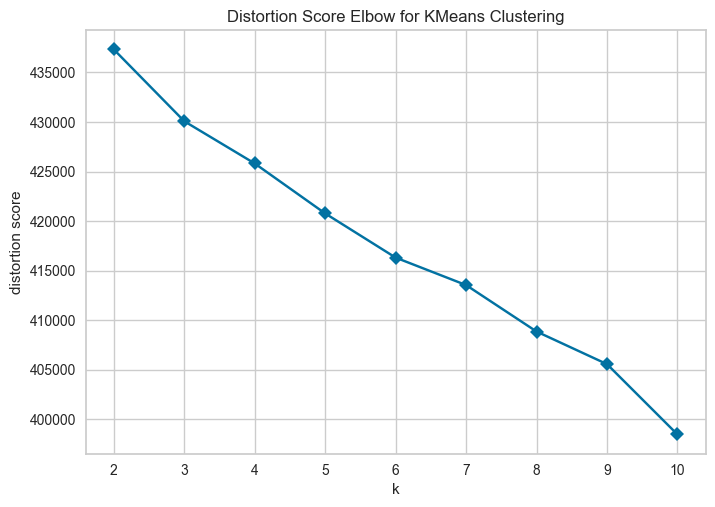

In [21]:
import duckdb
import pandas as pd
from pycaret.clustering import assign_model, create_model, plot_model, setup

# 1. Hent modelready_fact fra DuckDB
conn = duckdb.connect("./data/database/kostra_prod.duckdb", read_only=True)
df = conn.execute("SELECT * FROM modelready_fact").fetchdf()
conn.close()

# 2. Sett opp Clustering-eksperimentet
# Vi ignorerer ID-er, datofelter og tekstnavn slik at modellen kun lærer av numerisk atferd
exp_cluster = setup(
    data=df,
    ignore_features=[
        "accounting_period",
        "source_file",
        "batch_timestamp",
        "funksjon_navn",
        "kontonavn",
        "sektor_navn",
    ],
    normalize=True,  # Viktig for avstandsbasert klyngeanalyse
    session_id=42,
)

# 3. Test K-Means med 4 klynger (f.eks. Stabil, Høyvolatil, Underforbruk, Overforbruk)
kmeans = create_model("kmeans", num_clusters=4)

# 4. Legg klyngetilhørighet ('Cluster') tilbake på datasettet
df_clustered = assign_model(kmeans)

# 5. Visualiser klyngene
plot_model(kmeans, plot="cluster")  # 2D PCA/T-SNE plott
plot_model(kmeans, plot="elbow")  # Albue-graf for å finne optimalt antall klynger

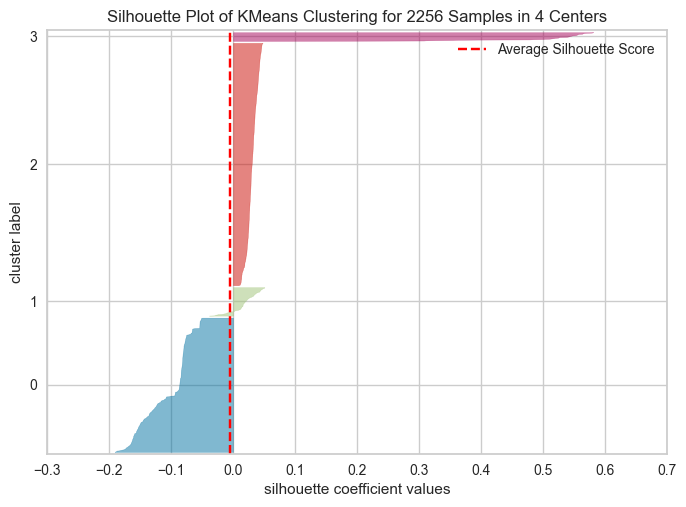

In [22]:
from pycaret.clustering import plot_model

# Vis Silhouette-plott for å finne den høyeste scoren
plot_model(kmeans, plot="silhouette")

In [ ]:
from pycaret.clustering import create_model, plot_model

# DBSCAN finner selv antall klynger basert på tetthet
dbscan = create_model("dbscan")

# Vis klyngene og støy/outliers
plot_model(dbscan, plot="cluster")

In [23]:
from pycaret.clustering import create_model, plot_model

# DBSCAN finner selv antall klynger basert på tetthet
dbscan = create_model("dbscan")

# Vis klyngene og støy/outliers
plot_model(dbscan, plot="cluster")

,Silhouette,Calinski-Harabasz,Davies-Bouldin,Homogeneity,Rand Index,Completeness
0,-0.1928,3.0738,1.4343,0,0,0
